Data Augmentation is a process of creating new training data from existing data by applying various transformations. This technique is commonly used in machine learning and deep learning to improve the performance of models by increasing the diversity of the training dataset. Some common data augmentation techniques include:
1. **Rotation**: Rotating images by a certain angle to create new variations of the original image.
2. **Flipping**: Flipping images horizontally or vertically to create mirror images.
3. **Scaling**: Resizing images to different scales while maintaining the aspect ratio.
4. **Translation**: Shifting images in the x or y direction to create new perspectives
5. **Cropping**: Randomly cropping sections of images to create new samples.
6. **Color Jittering**: Randomly changing the brightness, contrast, saturation, and hue of images to create variations in color.
7. **Noise Injection**: Adding random noise to images to make the model more robust to variations in input data.

so lets do some code work.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import os
import PIL
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

to get the flower images, dont simply run the below cell, change the `cache_dir` path there, add the path wherever you want to download that dataset. remember that you need that `r` as prefix.

In [2]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

data_dir = tf.keras.utils.get_file(
    'flower_photos',
    origin=dataset_url,
    cache_dir=r'D:\deep_learning_course\data\datasets',
    cache_subdir='',
    untar=True
)

print("Extracted to:", data_dir)

Extracted to: D:\deep_learning_course\data\datasets\flower_photos


In [3]:
data_dir

'D:\\deep_learning_course\\data\\datasets\\flower_photos'

change the path here too, add the path in which the image are installed. dont get confused by seeing flower_photos two times, its just how it installs, so you need the change the path before `r'... ...\flower_photos\flower_photos'`

In [4]:
import pathlib
data_dir = pathlib.Path(r'D:\deep_learning_course\data\datasets\flower_photos\flower_photos')
data_dir

WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos')

In [5]:
list(data_dir.glob('**/*.jpg'))[:5]

[WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/daisy/100080576_f52e8ee070_n.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/daisy/10140303196_b88d3d6cec.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/daisy/10172379554_b296050f82_n.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/daisy/10172567486_2748826a8b.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/daisy/10172636503_21bededa75_n.jpg')]

In [6]:
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

3670


In [7]:
roses = list(data_dir.glob('roses/*'))
roses[:5]

[WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/10090824183_d02c613f10_m.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/102501987_3cdb8e5394_n.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/10503217854_e66a804309.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/10894627425_ec76bbc757_n.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/110472418_87b6a3aa98_m.jpg')]

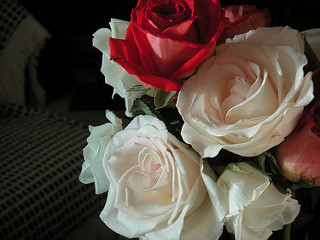

In [8]:
PIL.Image.open(str(roses[1]))

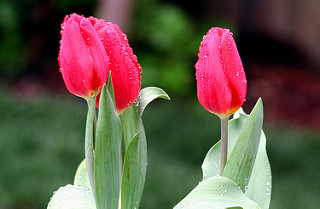

In [9]:
tulips = list(data_dir.glob('tulips/*'))
PIL.Image.open(str(tulips[0]))

Read flowers images from disk into numpy array using opencv

In [10]:
flowers_images_dict = {
    'roses': list(data_dir.glob('roses/*')),
    'daisy': list(data_dir.glob('daisy/*')),
    'dandelion': list(data_dir.glob('dandelion/*')),
    'sunflowers': list(data_dir.glob('sunflowers/*')),
    'tulips': list(data_dir.glob('tulips/*')),
}


In [11]:
flowers_labels_dict = {
    'roses': 0,
    'daisy': 1,
    'dandelion': 2,
    'sunflowers': 3,
    'tulips': 4,
}

In [12]:
flowers_images_dict['roses'][:5]

[WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/10090824183_d02c613f10_m.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/102501987_3cdb8e5394_n.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/10503217854_e66a804309.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/10894627425_ec76bbc757_n.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/110472418_87b6a3aa98_m.jpg')]

In [13]:
str(flowers_images_dict['roses'][0])

'D:\\deep_learning_course\\data\\datasets\\flower_photos\\flower_photos\\roses\\10090824183_d02c613f10_m.jpg'

In [14]:
img = cv2.imread(str(flowers_images_dict['roses'][0]))

In [15]:

img.shape

(240, 179, 3)

In [16]:
cv2.resize(img,(180,180)).shape

(180, 180, 3)

In [17]:
X, y = [], []

for flower_name, images in flowers_images_dict.items():
    for image in images:
        img = cv2.imread(str(image))
        resized_img = cv2.resize(img,(180,180))
        X.append(resized_img)
        y.append(flowers_labels_dict[flower_name])

In [18]:
X = np.array(X)
y = np.array(y)

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, random_state=0)

In [20]:
X_train_scaled = X_train / 255
X_test_scaled = X_test / 255

In [22]:
num_classes = 5

model = Sequential([
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPool2D(), 
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPool2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPool2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes)
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.fit(X_train_scaled, y_train, epochs=10)

Epoch 1/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 33s 370ms/step - accuracy: 0.3924 - loss: 1.4465
Epoch 2/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 25s 293ms/step - accuracy: 0.5727 - loss: 1.0587
Epoch 3/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 7s 87ms/step - accuracy: 0.6722 - loss: 0.8467
Epoch 4/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.7620 - loss: 0.6577
Epoch 5/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.8612 - loss: 0.4072
Epoch 6/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.9251 - loss: 0.2222
Epoch 7/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.9604 - loss: 0.1379
Epoch 8/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.9738 - loss: 0.0901
Epoch 9/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.9909 - loss: 0.0422
Epoch 10/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.9956 - loss: 0.0247


1. **Positional Shorthand in `Conv2D(16, 3, ...)`:**
In Keras, the first two parameters of `Conv2D` are `filters` and `kernel_size`. Instead of writing `filters=16, kernel_size=(3, 3)`, we passed them positionally (`16, 3`)—and when you pass a single integer `3` for `kernel_size`, Keras automatically expands it to `(3, 3)`.

2. **Empty `MaxPooling2D()`:**
- Its default `pool_size` is already `(2, 2)`, so `MaxPooling2D()` does the exact same thing as `MaxPooling2D((2, 2))`.
- `MaxPool2D()` and `MaxPooling2D` mean the same

3. **No Explicit `keras.Input(...)` Layer:**
When you omit `keras.Input(shape=...)`, Keras uses **deferred (lazy) building**: it leaves the layer weights unbuilt until the very first batch of `X_train_scaled` hits `model.fit()`, at which point it automatically inspects `X_train_scaled.shape[1:]` (here `(180, 180, 3)`) and builds the weights on the fly. *(Adding `keras.Input(shape=(180, 180, 3))` is still cleaner because it lets you call `model.summary()` immediately before training, though both produce the exact same model).*

4. **No `activation='softmax'` on the Final `Dense(num_classes)` + `from_logits=True`:**
Instead of turning the 5 raw output scores into probabilities inside the final `Dense` layer (`activation='softmax'`), this version outputs raw unscaled numbers (**logits**) and tells `SparseCategoricalCrossentropy(from_logits=True)` to apply softmax internally during loss calculation. Doing softmax inside the loss function is numerically more stable against floating-point rounding errors, though the math and predictions are identical.

In [25]:
model.evaluate(X_test_scaled,y_test)

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.6264 - loss: 2.3626


[2.362602472305298, 0.6263616681098938]

Here we see that while train accuracy is very high (99%), the test accuracy is significantly low (66.99%) indicating overfitting. Let's make some predictions before we use data augmentation to address overfitting

In [26]:
predictions = model.predict(X_test_scaled)
predictions

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step


array([[  1.5907089 ,  15.701178  ,   1.2667694 , -23.084076  ,
        -12.329604  ],
       [  8.247042  ,  -1.0050753 ,  -9.66658   ,  -5.862363  ,
          5.6588426 ],
       [ -3.4436107 ,   3.2393782 ,  10.955216  ,  -8.4138975 ,
         -8.238426  ],
       ...,
       [ -6.0363317 ,  -8.29021   ,  -0.20981681,   0.28615218,
          4.4253407 ],
       [ -0.7803048 ,   1.3599318 ,  -6.151828  ,  -7.611677  ,
         -2.9823873 ],
       [  0.4422307 , -11.607664  ,   4.147811  ,   5.631071  ,
          4.5077033 ]], shape=(918, 5), dtype=float32)

In [27]:
score = tf.nn.softmax(predictions[0])

In [28]:
np.argmax(score)

np.int64(1)

In [29]:
y_test[0]

np.int64(1)

Improve Test Accuracy Using Data Augmentation

In [31]:
img_height = 180
img_width = 180

data_augmentation = keras.Sequential([
    keras.Input(shape=(img_height, img_width, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])


Original Image

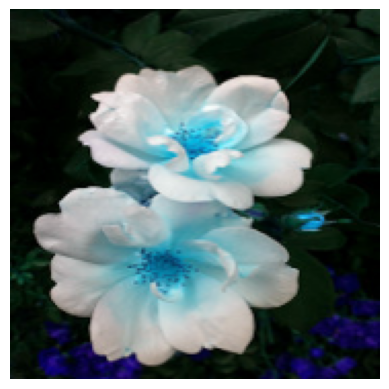

In [32]:
plt.axis('off')
plt.imshow(X[0])

Newly generated training sample using data augmentation

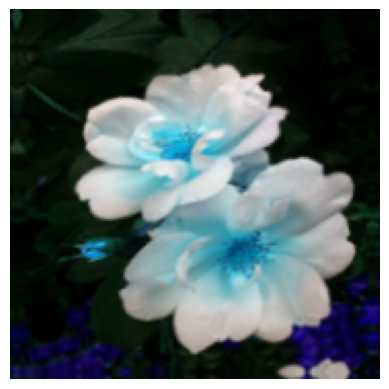

In [33]:
plt.axis('off')
plt.imshow(data_augmentation(X)[0].numpy().astype("uint8"))

### Train the model using data augmentation and a drop out layer

In [34]:
num_classes = 5

model = Sequential([
  data_augmentation,
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Dropout(0.2),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes)
])

model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
              
model.fit(X_train_scaled, y_train, epochs=10)    

Epoch 1/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 30s 331ms/step - accuracy: 0.4164 - loss: 1.3865
Epoch 2/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 35s 404ms/step - accuracy: 0.5854 - loss: 1.0512
Epoch 3/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 35s 409ms/step - accuracy: 0.6101 - loss: 0.9814
Epoch 4/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 34s 394ms/step - accuracy: 0.6446 - loss: 0.9145
Epoch 5/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 42s 403ms/step - accuracy: 0.6682 - loss: 0.8588
Epoch 6/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 34s 395ms/step - accuracy: 0.6937 - loss: 0.8086
Epoch 7/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 41s 400ms/step - accuracy: 0.6999 - loss: 0.7669
Epoch 8/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 34s 400ms/step - accuracy: 0.7057 - loss: 0.7517
Epoch 9/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 34s 395ms/step - accuracy: 0.7227 - loss: 0.7181
Epoch 10/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 42s 400ms/step - accuracy: 0.7282 - loss: 0.6968


In [35]:
model.evaluate(X_test_scaled,y_test)

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6667 - loss: 0.9173


[0.9172875285148621, 0.6666666865348816]

You can see that by using data augmentation and drop out layer the accuracy of test set predictions is increased to 66%